# SoCal ZIP-by-Time Market Score Model

This notebook is the executable companion to the assignment report. It performs the required latest-2025 calibration and every optional task: all-period scoring, a time-series example, feature interpretation, temporal validation, and geographic distribution-shift analysis.

The score is contemporaneous and descriptive. It is not a forecast.

In [1]:
from pathlib import Path
import os
import sys
import tempfile

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "socal-market-score-matplotlib"))

import pandas as pd
from IPython.display import Image, display

from socal_market_score.workflow import run_workflow

INPUT_PATH = ROOT / "data" / "raw" / "SoCal - Real Estate Market Metrics - ZIP×Time Score Series.xlsx"
OUTPUT_DIR = ROOT / "outputs"
FIGURE_DIR = ROOT / "figures"
REPORT_PATH = ROOT / "REPORT.md"

## 1. Rebuild the complete solution

All preprocessing is learned inside model pipelines. Candidate hyperparameters are tuned inside the inner cross-validation loop, and the outer loop provides honest model-comparison predictions.

In [2]:
context = run_workflow(
    input_path=INPUT_PATH,
    output_dir=OUTPUT_DIR,
    figure_dir=FIGURE_DIR,
    report_path=REPORT_PATH,
)

pd.Series(context["oof_metrics"], name="Repeated nested-CV metric")

Loading and validating workbook...


Running repeated nested model comparison...


Nested CV: Dummy median | current levels: MAE=13.204, RMSE=17.235


Nested CV: Ridge | current levels: MAE=7.173, RMSE=9.753


Nested CV: Ridge | trailing-year levels: MAE=7.260, RMSE=10.000


Nested CV: Elastic net | current levels: MAE=7.151, RMSE=9.715


... (8 outputs left out)

Running geographic stress test and interpretation diagnostics...


Writing outputs and figures...


Workflow complete.


mae         7.173024
rmse        9.752655
r2          0.648715
spearman    0.825571
Name: Repeated nested-CV metric, dtype: float64

## 2. Data eligibility and coverage

In [3]:
pd.Series(context["audit"], name="Value").to_frame()

,Value
source_rows,12445
source_columns,54
unique_zips,764
period_start,2012-03-31
period_end,2025-12-31
unique_period_end_dates,166
reference_rows,143
numeric_reference_scores,120
latest_2025_rows,524
calibration_rows,83


The calibration rows are the intersection of (1) numeric reference scores and (2) ZIPs with at least one 2025 record. Each ZIP's latest row is the maximum `PERIOD_END` within calendar year 2025. ZIPs without 2025 records are excluded from latest scoring, as required.

In [4]:
context["exclusions"].head(15)

,Zip Code,City,County,Market Score raw,Exclusion reason
0,90004,Los Angeles,Los Angeles County,46,No 2025 market record
1,90008,Los Angeles,Los Angeles County,55,No 2025 market record
2,90011,Los Angeles,Los Angeles County,50,No 2025 market record
3,90012,Los Angeles,Los Angeles County,47,No 2025 market record
4,90013,Los Angeles,Los Angeles County,28,No 2025 market record
5,90018,Los Angeles,Los Angeles County,36,No 2025 market record
6,90021,Los Angeles,Los Angeles County,/,Reference score is not numeric; No 2025 market...
7,90022,Los Angeles,Los Angeles County,68,No 2025 market record
8,90026,Los Angeles,Los Angeles County,74,No 2025 market record
9,90029,Los Angeles,Los Angeles County,49,No 2025 market record


## 3. Research-backed model search

The candidate set covers Ridge, Elastic Net, Huber regression, PLS, RBF SVR, random forest, extra trees, and histogram gradient boosting, plus a median baseline.

- Ridge: https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification
- Elastic Net: https://rss.onlinelibrary.wiley.com/doi/10.1111/j.1467-9868.2005.00503.x
- Random forests: https://doi.org/10.1023/A:1010933404324
- Gradient boosting: https://doi.org/10.1214/aos/1013203451
- Nested CV bias: https://pubmed.ncbi.nlm.nih.gov/16504092/
- Data leakage: https://scikit-learn.org/stable/common_pitfalls.html#data-leakage

The one-standard-error rule selects the simplest model statistically close to the best mean outer-fold MAE.

### Feature-representation screen

In [5]:
context["feature_representation_screen"]

,representation,feature_count,mae_mean,mae_std,rmse_mean,r2_mean
0,Current levels,12,7.171749,1.233941,9.479211,0.620666
1,Trailing-year levels,12,7.295726,1.146879,9.636304,0.604284
2,Trailing-year levels + MoM + YoY,36,7.810045,1.374547,10.089563,0.560488
3,Trailing-year levels + YoY,24,7.875837,1.237261,10.238382,0.547420
4,Current levels + YoY,24,7.998047,1.492816,10.900650,0.500644
5,Current levels + MoM + YoY,36,8.619048,1.380219,11.311910,0.462990


### Repeated nested-CV model comparison

In [6]:
comparison_columns = [
    "candidate", "outer_mae_mean", "outer_mae_se", "oof_mae",
    "oof_rmse", "oof_r2", "oof_spearman", "within_one_se", "selected",
]
context["comparison"][comparison_columns]

,candidate,outer_mae_mean,outer_mae_se,oof_mae,oof_rmse,oof_r2,oof_spearman,within_one_se,selected
0,RBF SVR | current levels,7.084547,0.289961,6.702645,9.534265,0.664271,0.823681,True,False
1,Elastic net | current levels,7.292000,0.252806,7.151353,9.714856,0.651433,0.830527,True,False
2,Ridge | current levels,7.293928,0.247556,7.173024,9.752655,0.648715,0.825571,True,True
3,PLS | current levels,7.312836,0.224191,7.208933,9.410069,0.672961,0.831693,True,False
4,Huber | current levels,7.321836,0.233496,7.190418,9.639902,0.656791,0.829446,True,False
5,Extra trees | current levels,7.338820,0.275853,7.267157,9.621366,0.658109,0.812624,True,False
6,Huber | trailing-year levels,7.367154,0.235711,7.133817,9.822616,0.643657,0.800758,True,False
7,Ridge | trailing-year levels,7.466359,0.237509,7.260284,9.999941,0.630675,0.785049,False,False
8,Random forest | current levels,7.748683,0.306435,7.647435,9.958285,0.633745,0.787087,False,False
9,Histogram gradient boosting | current levels,8.094274,0.354127,7.584188,10.087595,0.624172,0.786184,False,False


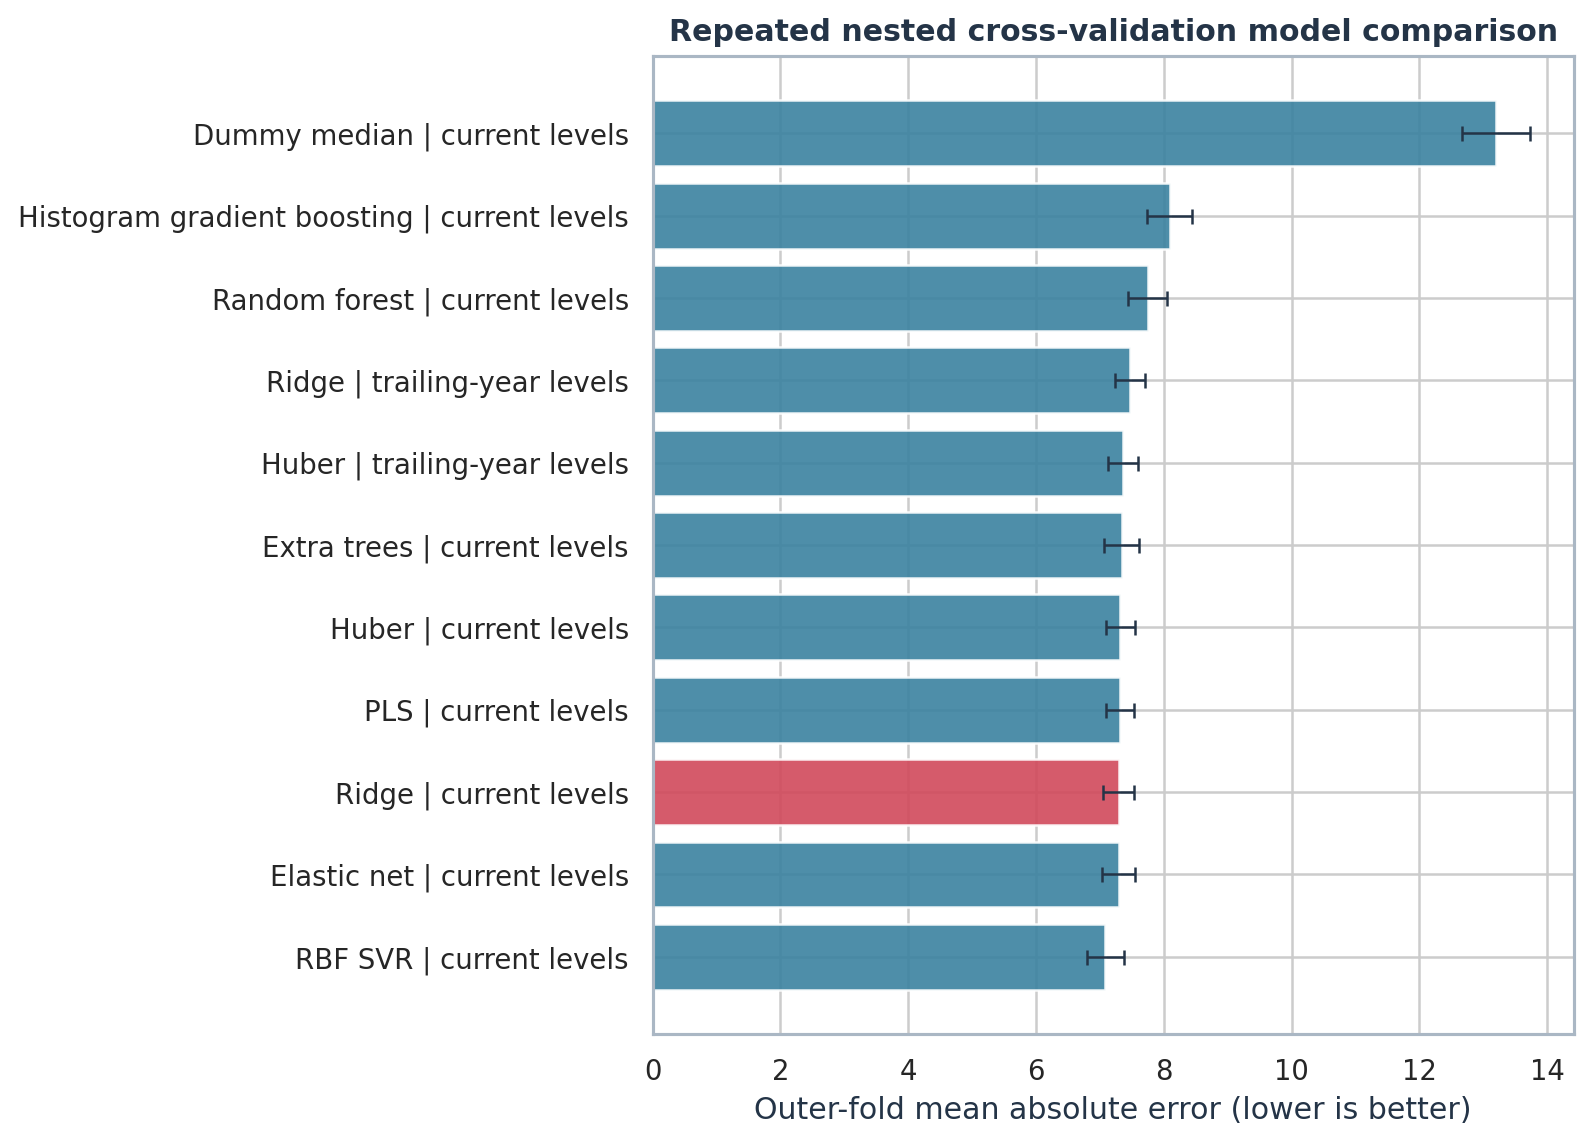

In [7]:
display(Image(filename=str(FIGURE_DIR / "model_comparison.png")))

## 4. Reference-score validation

`y_pred` in the required evaluation CSV is the mean repeated nested-CV out-of-fold prediction for each labeled ZIP, not an in-sample fitted value.

In [8]:
evaluation = context["evaluation"].copy()
evaluation[["Zip Code", "City", "County", "PERIOD_END", "y_true", "y_pred", "residual"]].head(15)

,Zip Code,City,County,PERIOD_END,y_true,y_pred,residual
0,90001,Los Angeles,Los Angeles County,2025-12-31,49.0,59.659907,-10.659907
1,90002,Los Angeles,Los Angeles County,2025-06-30,69.0,54.199704,14.800296
2,90003,Los Angeles,Los Angeles County,2025-07-31,57.0,47.378280,9.621720
3,90005,Los Angeles,Los Angeles County,2025-07-31,31.0,41.564600,-10.564600
4,90006,Los Angeles,Los Angeles County,2025-01-31,49.0,52.933801,-3.933801
5,90007,Los Angeles,Los Angeles County,2025-04-30,15.0,42.983884,-27.983884
6,90010,Los Angeles,Los Angeles County,2025-07-31,44.0,41.941743,2.058257
7,90014,Los Angeles,Los Angeles County,2025-09-30,17.0,51.797284,-34.797284
8,90015,Los Angeles,Los Angeles County,2025-05-31,27.0,38.849510,-11.849510
9,90016,Los Angeles,Los Angeles County,2025-08-31,63.0,64.524168,-1.524168


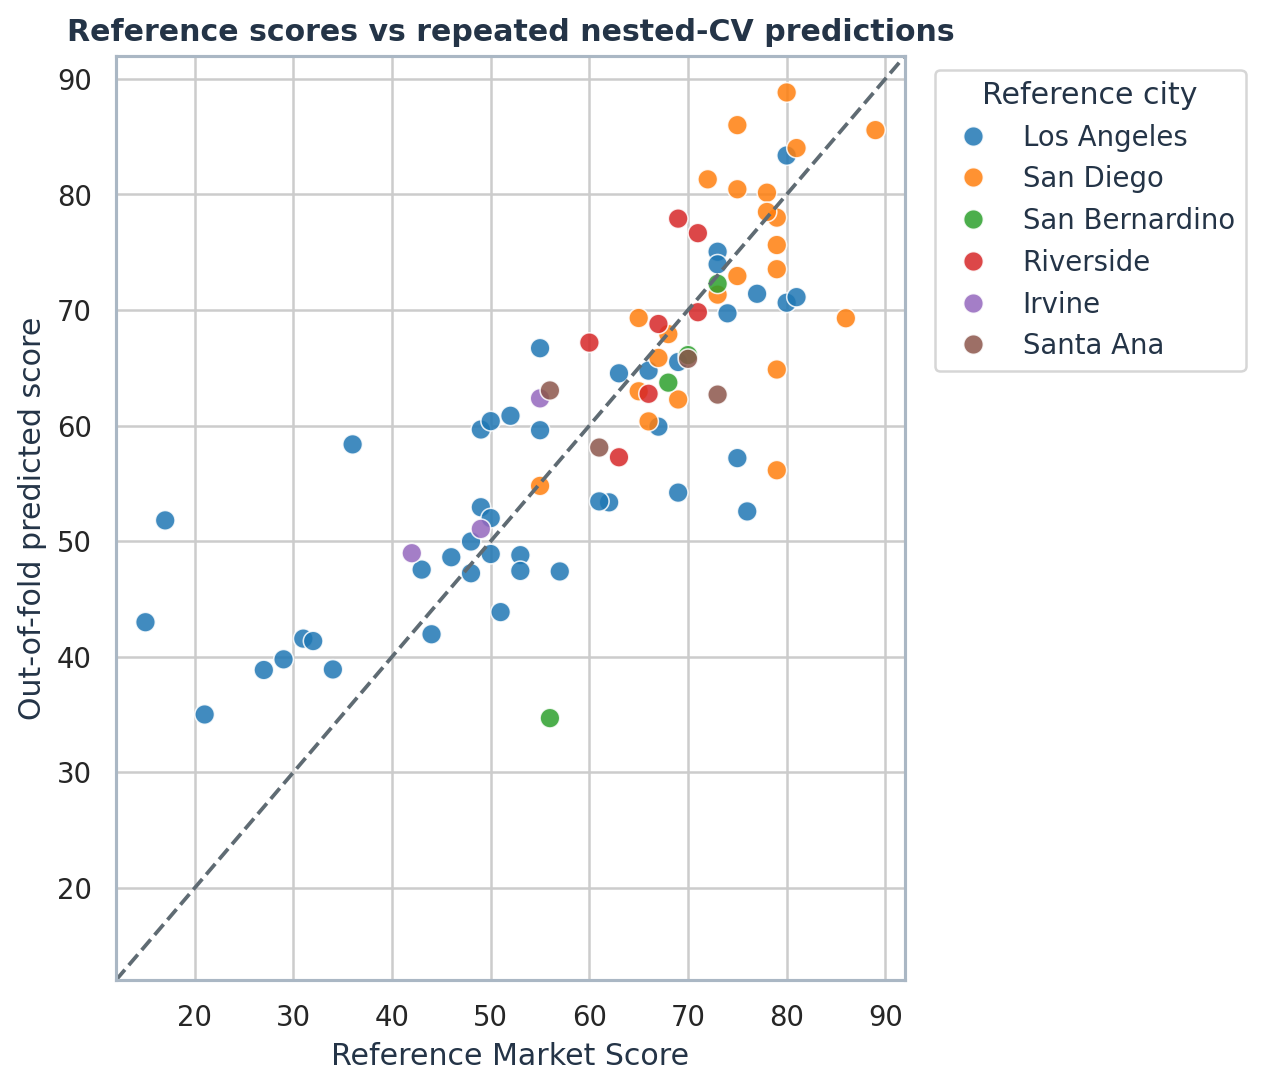

In [9]:
display(Image(filename=str(FIGURE_DIR / "reference_validation.png")))

## 5. Feature importance and coefficient direction

In [10]:
context["feature_importance"].head(12)

,feature,permutation_mae_increase_mean,permutation_mae_increase_std,standardized_coefficient_mean,standardized_coefficient_std,positive_coefficient_share
0,MEDIAN_DOM,2.745198,1.002476,-5.692921,0.799958,0.00
1,INVENTORY,1.872355,1.396739,-4.178391,2.083111,0.00
2,AVG_SALE_TO_LIST,0.726723,0.484214,2.771990,0.553613,1.00
3,OFF_MARKET_IN_TWO_WEEKS,0.670139,0.446800,2.871336,0.871442,1.00
4,SOLD_ABOVE_LIST,0.589533,0.396751,2.217211,0.781465,1.00
5,MEDIAN_SALE_PRICE,0.498733,1.038014,-1.682793,2.099932,0.04
6,PENDING_SALES,0.466710,0.576285,2.394056,1.087925,1.00
7,HOMES_SOLD,0.392533,0.418712,1.936270,1.041123,0.96
8,NEW_LISTINGS,0.262262,0.471863,1.772128,1.534611,1.00
9,MEDIAN_LIST_PPSF,0.146674,0.491533,0.132196,1.626713,0.44


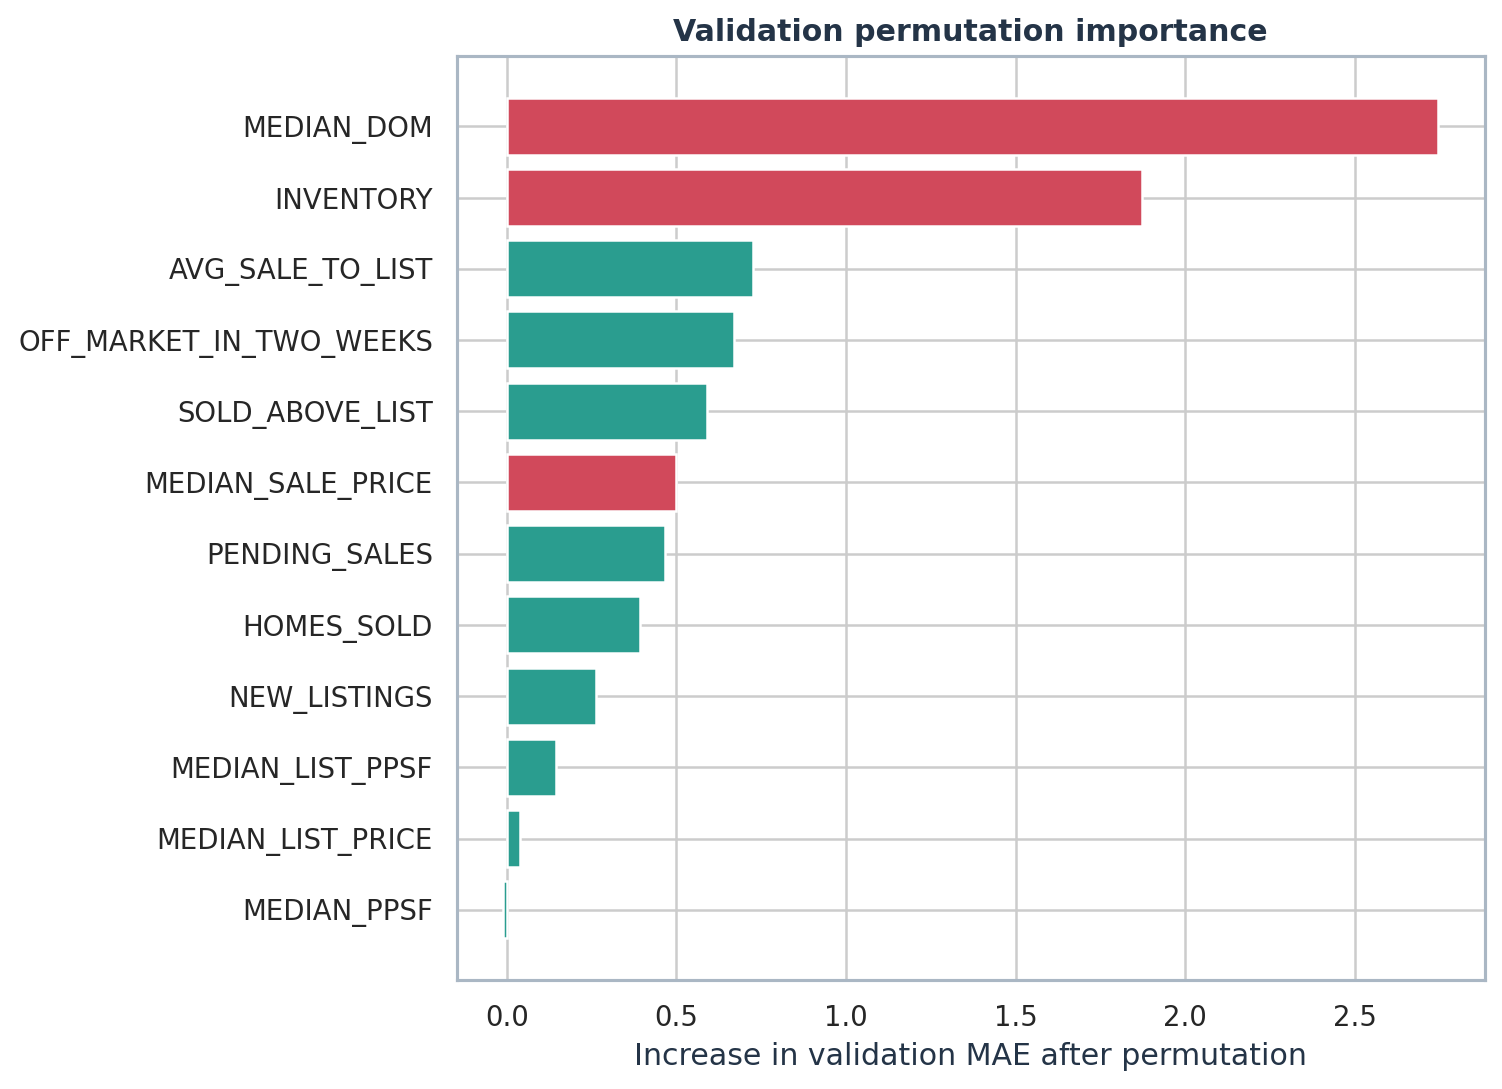

In [11]:
display(Image(filename=str(FIGURE_DIR / "feature_importance.png")))

## 6. Latest-period outputs and sanity checks

In [12]:
latest_scores = pd.read_csv(OUTPUT_DIR / "scores_latest_all_zips.csv")
display(latest_scores.nlargest(10, "MarketScore_hat"))
display(latest_scores.nsmallest(10, "MarketScore_hat"))

,Zip Code,City,County,PERIOD,MarketScore_hat
448,92683,Westminster,Orange County,2025-09-30,89.28
93,90630,Cypress,Orange County,2025-01-31,88.75
290,92114,San Diego,San Diego County,2025-09-30,88.58
508,93455,Santa Maria,Santa Barbara County,2025-10-31,87.34
489,93033,Oxnard,Ventura County,2025-12-31,87.28
218,91775,San Gabriel,Los Angeles County,2025-08-31,86.71
303,92154,San Diego,San Diego County,2025-08-31,86.50
323,92249,Heber,Imperial County,2025-12-31,86.18
232,91910,Chula Vista,San Diego County,2025-12-31,85.82
229,91902,Bonita,San Diego County,2025-11-30,85.37


,Zip Code,City,County,PERIOD,MarketScore_hat
48,90213,Beverly Hills,Los Angeles County,2025-04-30,30.25
10,90017,Los Angeles,Los Angeles County,2025-06-30,30.30
355,92326,Crest Park,San Bernardino County,2025-10-31,32.57
64,90265,Malibu,Los Angeles County,2025-05-31,35.40
8,90015,Los Angeles,Los Angeles County,2025-05-31,36.69
42,90077,Los Angeles,Los Angeles County,2025-09-30,37.61
270,92066,Ranchita,San Diego County,2025-09-30,37.76
134,91123,Pasadena,Los Angeles County,2025-02-28,38.15
5,90007,Los Angeles,Los Angeles County,2025-04-30,38.64
45,90210,Beverly Hills,Los Angeles County,2025-12-31,38.72


In [13]:
context["sanity_checks"]

,signal,rows,expected_direction,spearman_correlation,direction_aligned
0,Sold above list share,524,positive,0.713676,True
1,Average sale-to-list ratio,524,positive,0.753717,True
2,Median days on market,524,negative,-0.775912,True
3,Inventory,511,negative,-0.060374,True
4,List-price drop proxy,510,negative,-0.047038,True


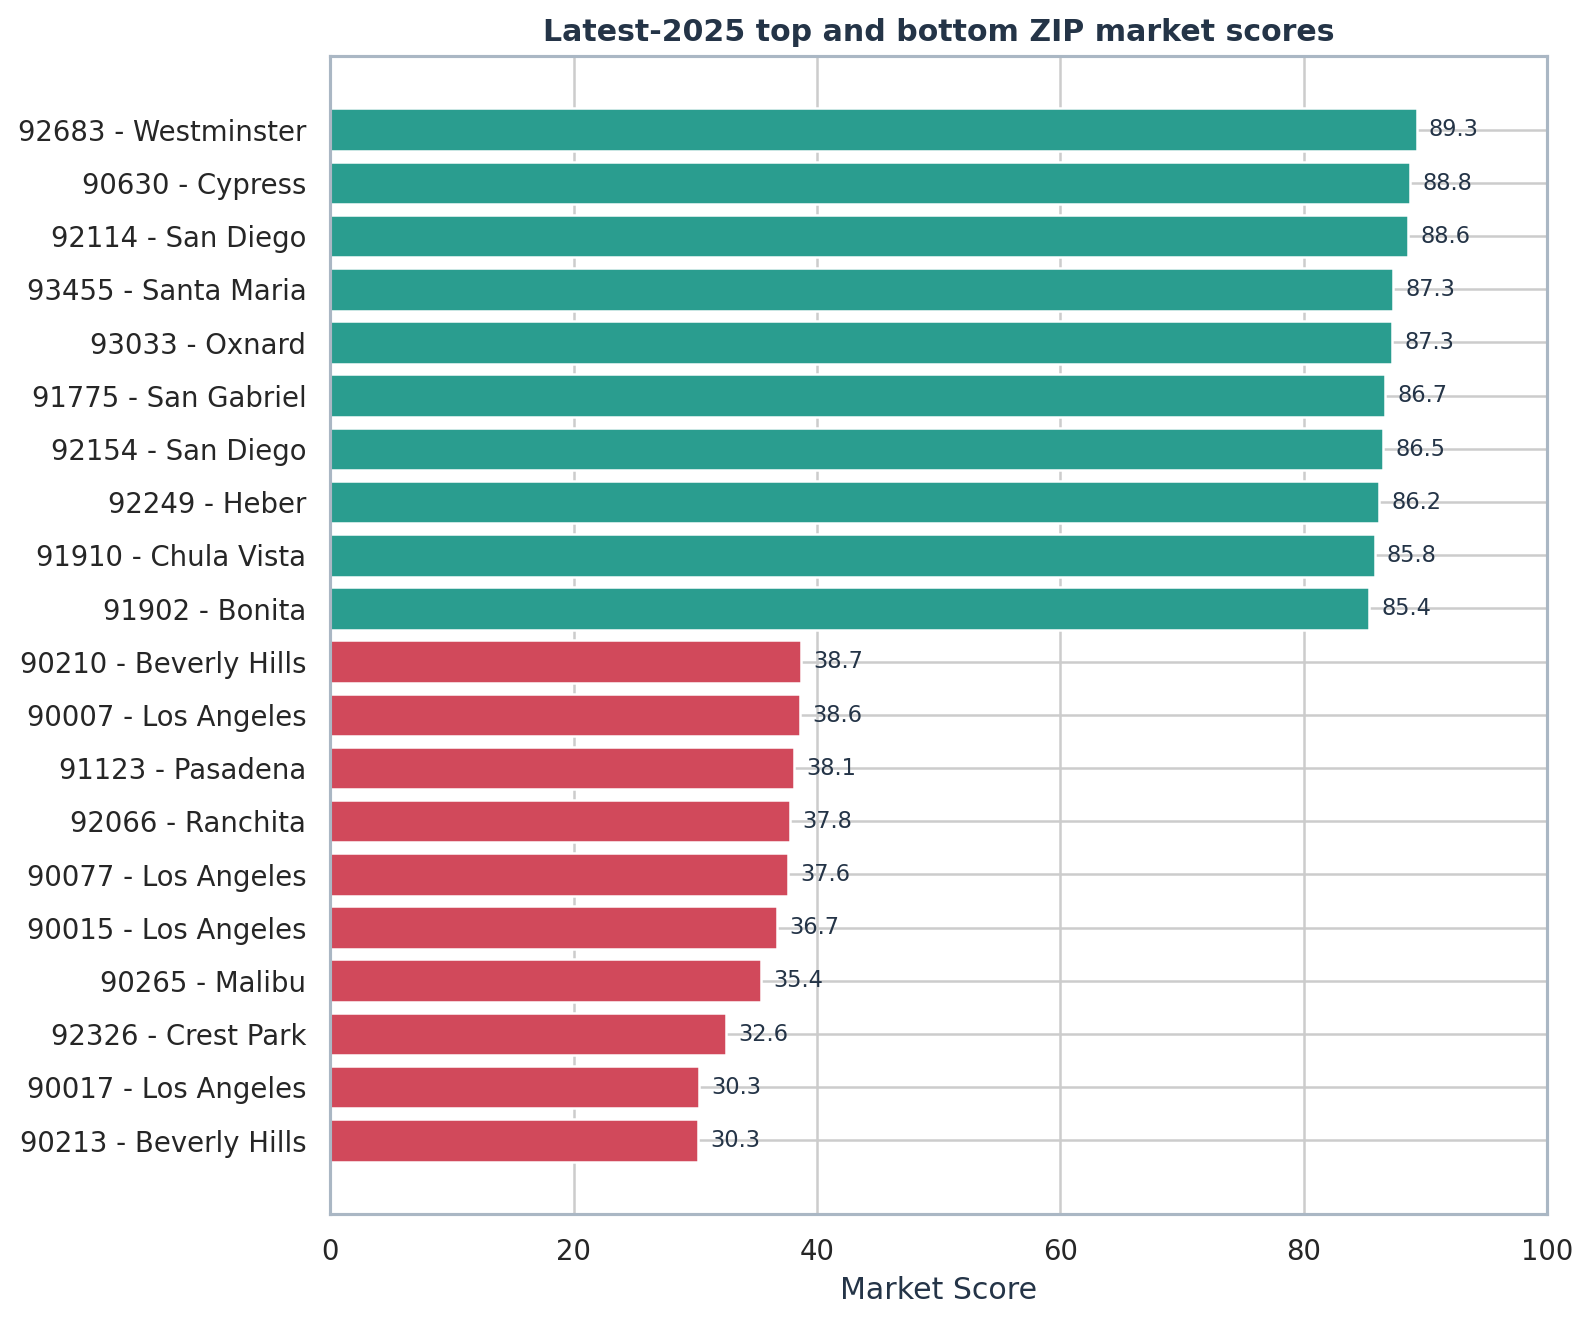

In [14]:
display(Image(filename=str(FIGURE_DIR / "top_bottom_latest.png")))

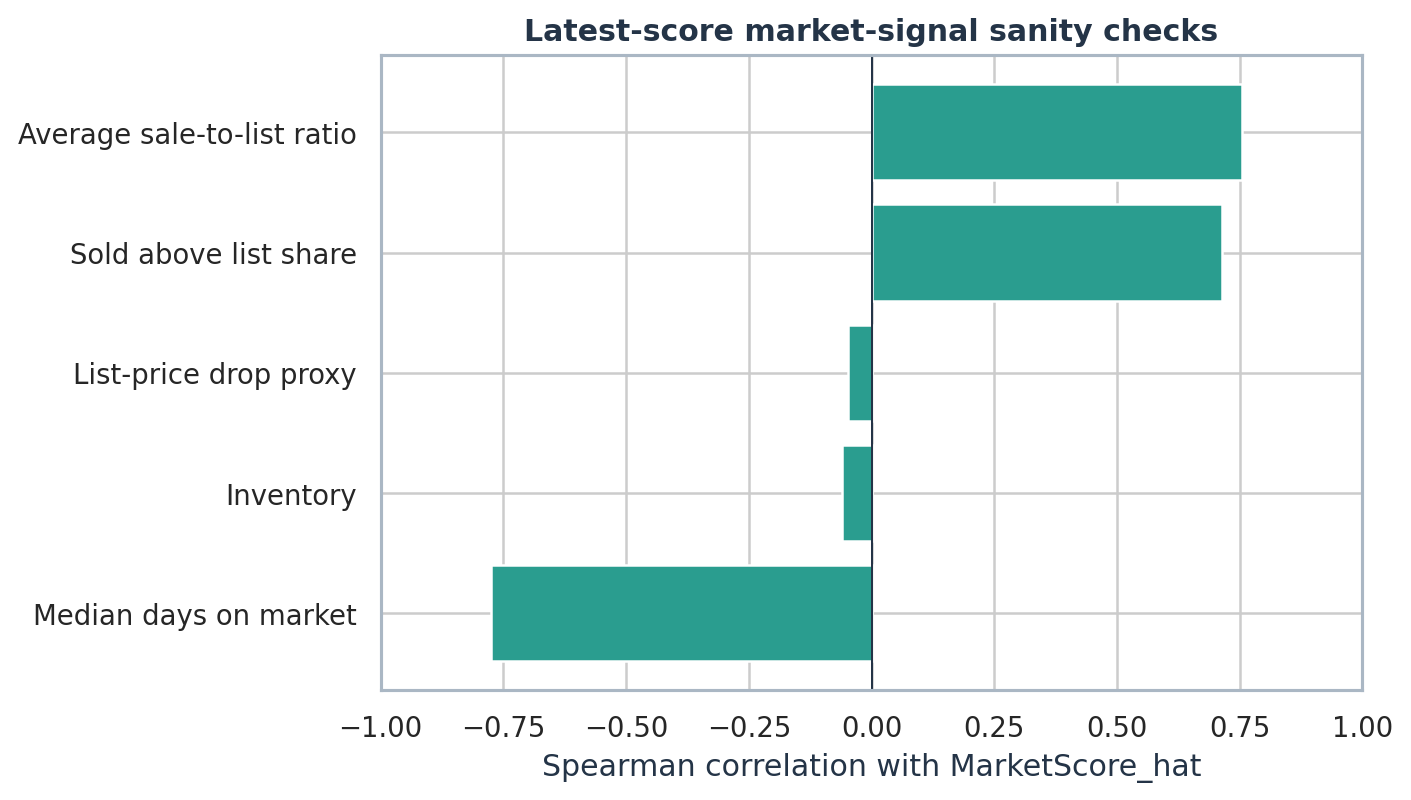

In [15]:
display(Image(filename=str(FIGURE_DIR / "sanity_checks.png")))

## 7. Optional all-period score series and stability

In [16]:
pd.Series(context["stability_summary"], name="Value").to_frame()

,Value
consecutive_comparisons,11681.000000
median_absolute_consecutive_change,5.164204
p95_absolute_consecutive_change,19.154711
share_consecutive_change_over_10,0.234569
share_consecutive_change_over_15,0.102645
year_over_year_comparisons,4875.000000
median_absolute_year_over_year_change,5.767180
p95_absolute_year_over_year_change,19.992645
share_year_over_year_change_over_15,0.118564


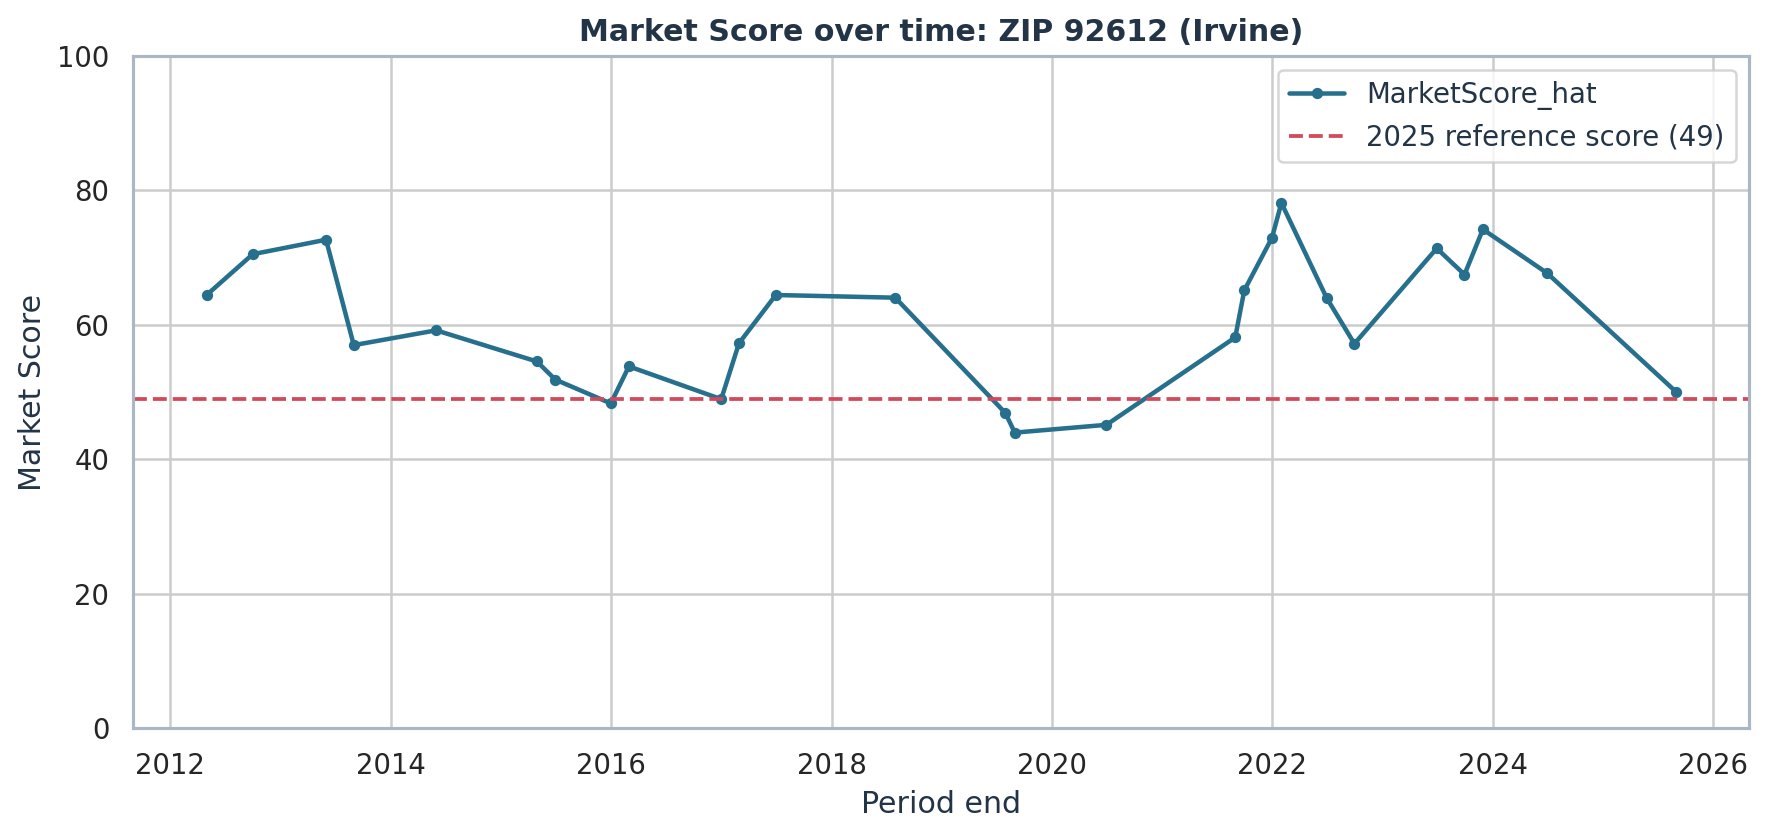

In [17]:
display(Image(filename=str(FIGURE_DIR / "score_trend_example.png")))

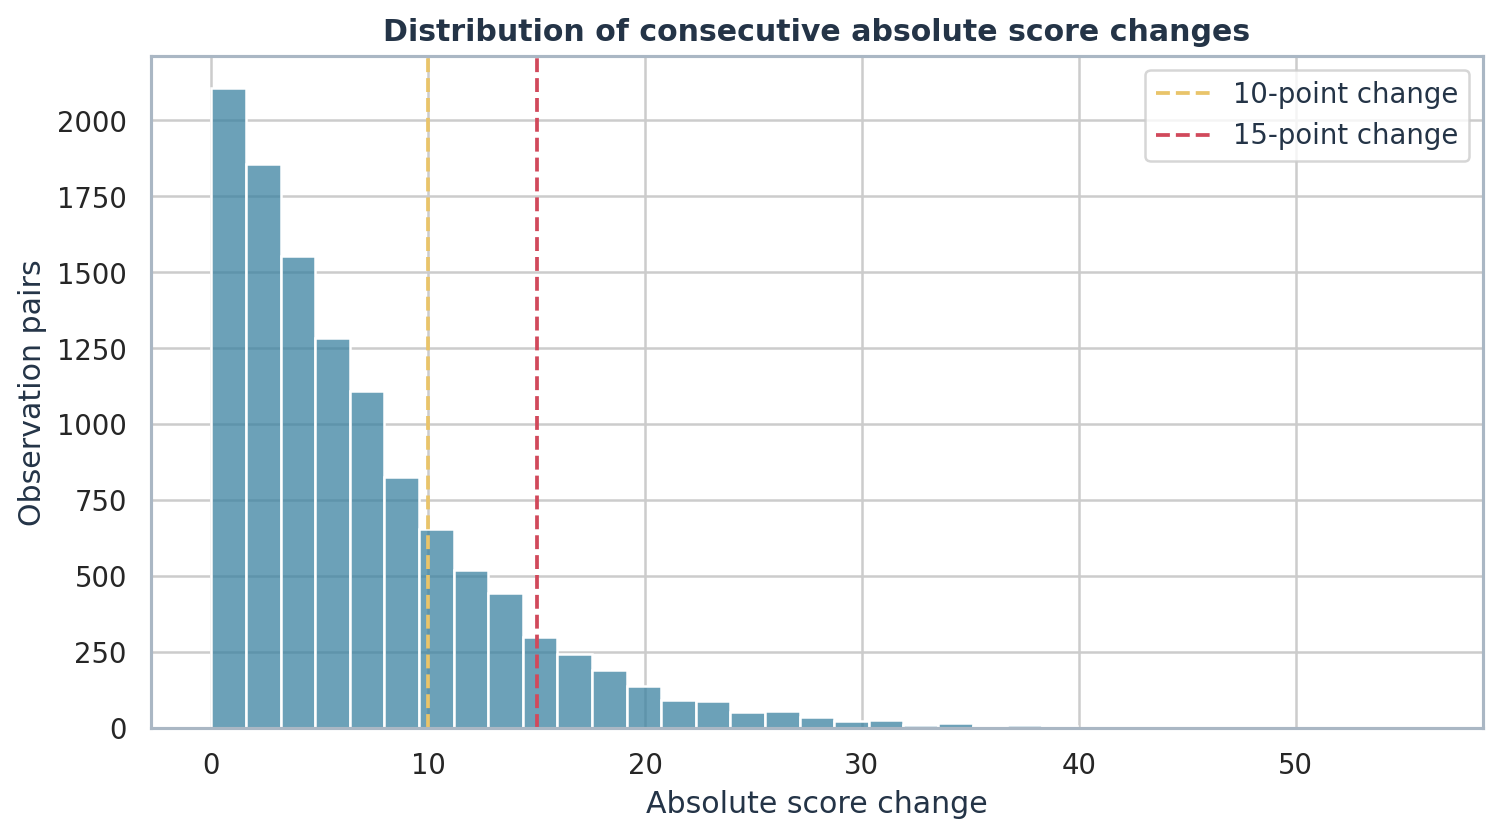

In [18]:
display(Image(filename=str(FIGURE_DIR / "temporal_stability.png")))

## 8. Optional distribution-shift analysis

Feature-level standardized differences and KS statistics are complemented by adversarial validation. A high adversarial AUC means the selected reference ZIPs can be distinguished from the other latest-2025 ZIPs, which warns that random CV may not fully describe deployment risk.

In [19]:
pd.Series(context["shift_summary"], name="Value").to_frame()

,Value
target_rows,441.000000
adversarial_auc_mean,0.758747
adversarial_auc_std,0.062824
calibration_distance_p95_threshold,2.550052
target_ood_share,0.124717
features_abs_smd_over_0_5,2.000000


In [20]:
context["feature_shift"].head(12)

,feature,calibration_mean,target_mean,standardized_mean_difference,absolute_standardized_mean_difference,ks_statistic,ks_p_value,wasserstein_distance
0,MEDIAN_PPSF,0.651218,0.476497,-0.656142,0.656142,0.316559,0.000001,0.178737
1,MEDIAN_LIST_PPSF,0.640507,0.481167,-0.585800,0.585800,0.302104,0.000004,0.161908
2,MEDIAN_SALE_PRICE,0.586212,0.493062,-0.329746,0.329746,0.165806,0.037493,0.094660
3,INVENTORY,0.583185,0.498360,-0.308063,0.308063,0.178724,0.020282,0.090277
4,OFF_MARKET_IN_TWO_WEEKS,0.427250,0.514126,0.307692,0.307692,0.174020,0.025430,0.087146
5,NEW_LISTINGS,0.569926,0.501363,-0.242506,0.242506,0.122667,0.224492,0.070926
6,MEDIAN_LIST_PRICE,0.561004,0.496628,-0.224429,0.224429,0.150743,0.075229,0.066871
7,AVG_SALE_TO_LIST,0.444009,0.499198,0.198059,0.198059,0.161790,0.045363,0.059095
8,HOMES_SOLD,0.552853,0.499895,-0.186453,0.186453,0.117340,0.266691,0.057656
9,PENDING_SALES,0.540724,0.503745,-0.130663,0.130663,0.087439,0.624442,0.044990


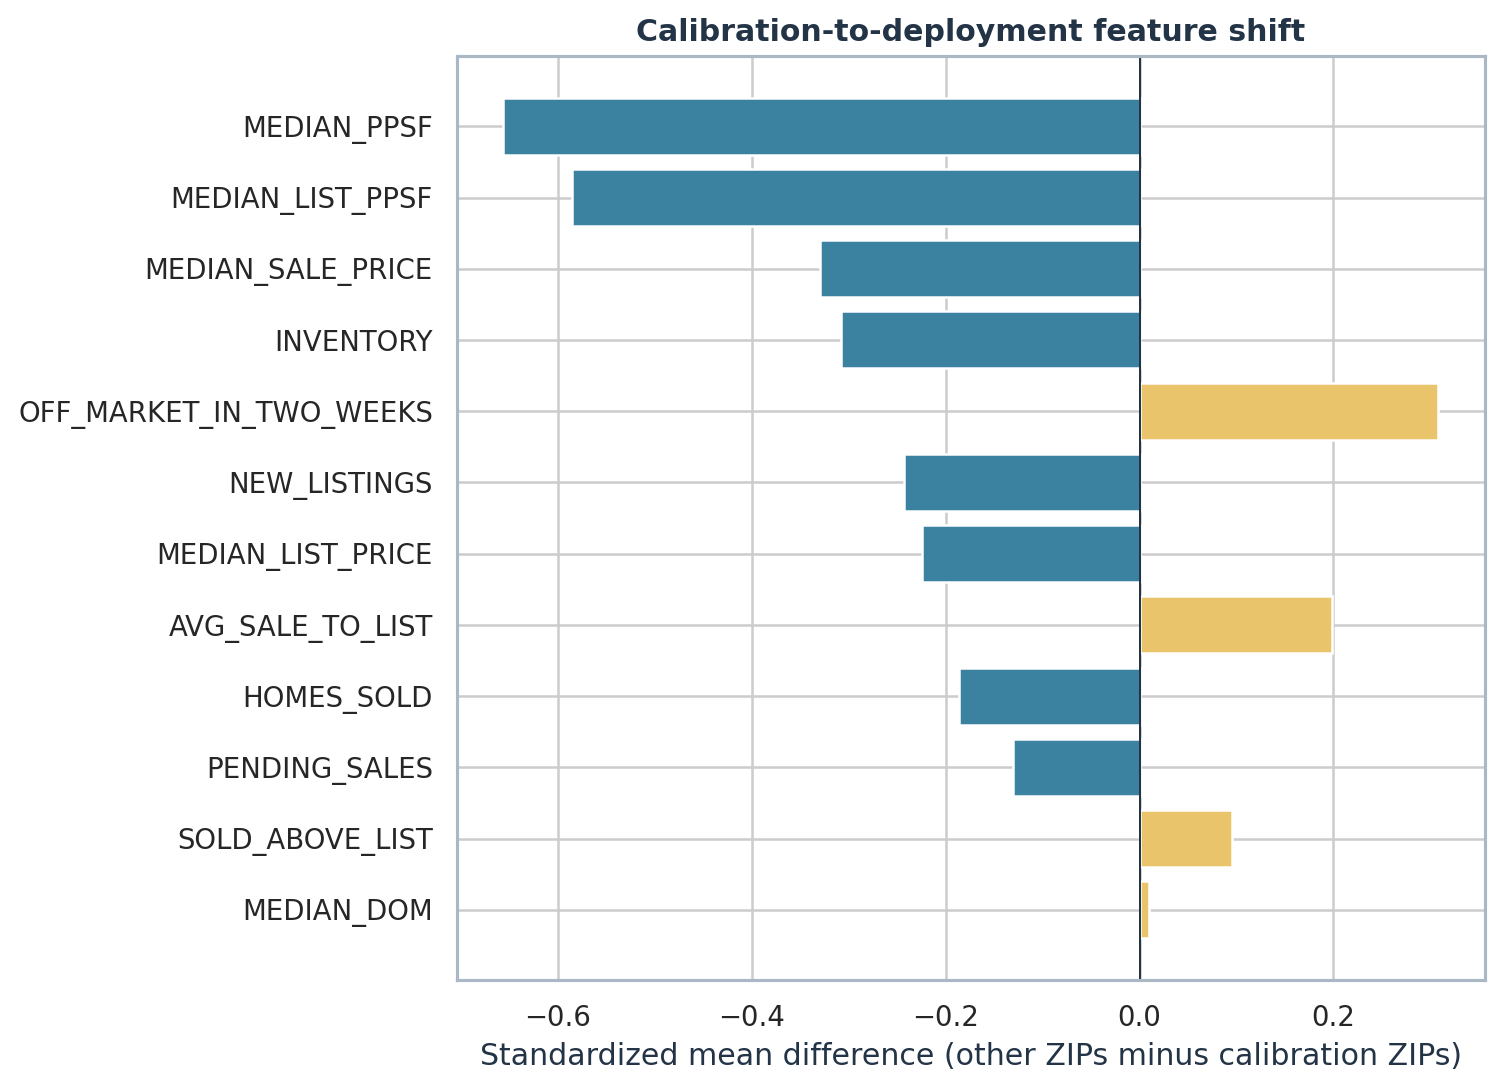

In [21]:
display(Image(filename=str(FIGURE_DIR / "distribution_shift.png")))

## 9. Deliverable audit

In [22]:
required_files = [
    OUTPUT_DIR / "scores_latest_select_zips_eval.csv",
    OUTPUT_DIR / "scores_latest_all_zips.csv",
    OUTPUT_DIR / "scores_all_periods.csv",
    OUTPUT_DIR / "market_score_model.joblib",
    REPORT_PATH,
]
pd.DataFrame({
    "file": [str(path.relative_to(ROOT)) for path in required_files],
    "exists": [path.exists() for path in required_files],
    "bytes": [path.stat().st_size if path.exists() else 0 for path in required_files],
})

,file,exists,bytes
0,outputs/scores_latest_select_zips_eval.csv,True,4943
1,outputs/scores_latest_all_zips.csv,True,27152
2,outputs/scores_all_periods.csv,True,642238
3,outputs/market_score_model.joblib,True,2887
4,REPORT.md,True,13204


## 10. Conclusion

The selected regularized model balances predictive accuracy, stability, and interpretability in a small, geographically concentrated label set. The technical report contains the full measured results, limitations, and production recommendations. In particular, the detected geographic covariate shift should be addressed with broader reference labeling before the score is used for high-stakes decisions.